# Closed-loop latency: Windows Audio vs DirectSound

Each saline test feeds an audio test pulse to the headstage, lets the Ripple Detector fire on it and
the stimulator respond. The audio pulse is also fed to a GPIO input, so every trial has three
timestamps on one clock: the **digital input** (TTL6, the test pulse produced), the **OpenEphys
detection time** (TTL8, the Ripple Detector firing) and the **trigger** (TTL2, the stimulator's output,
recorded as a pair of 0.1 ms pulses). This notebook measures, per session,

- **digital input → OpenEphys detection time**: how long detection took on the signal the detector
  reads (broadband or LFP);
- **OpenEphys detection time → trigger**: the wait for the trigger, which goes out on the next tick of
  a 10 ms grid with the Windows Audio device;
- **digital input → trigger**: the whole loop;

and compares the sessions stage by stage. This copy compares four broadband sessions (detector input `A_CH5`) from `SalineLatencyTest1015`, two per Open
Ephys audio device, each device at a small buffer and at 480 samples: **Windows Audio** at 48 kHz (`WindowsSound/10-23-24`,
144 samples = 3 ms; `10-27-24`, 480 = 10 ms) and **DirectSound** at 96 kHz (`DirectAudio/10-14-54`, 64 = 0.67 ms;
`10-18-46`, 480 = 5 ms). The last section pools each device, which mixes the two buffer sizes: read it beside the
per-session rows. Sessions not on the drive are listed and left out. `latency_comparison.ipynb` holds the earlier
sessions, `latency_comparison_buffer.ipynb` the three buffer-size sessions of 10-15. Add a session by adding a line to `SESSIONS`; everything
below is computed for every entry. The per-session notebooks (`event_aligned_…ipynb`) show each
session in detail; this one only compares.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import re
from dataanalyzer import io as dio

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Sessions

`input` is the stream and channel the Ripple Detector reads; it is only used to draw what the detector
saw. The Open Ephys audio buffer size (settings.xml `<AUDIO bufferSize>`, samples at 48 kHz) paces the
GUI's processing and is listed for every session: 192 (4 ms) unless the label says otherwise. The TTL lines are found by source processor and line number on the broadband stream, so the
sessions do not need to list them in the same order.

In [2]:
BASE = Path("/Volumes/Extreme/RippleDetection/Saline")
SESSIONS = [
    dict(label="Windows 144 @ 48k (10-23-24)", group="Windows Audio", path=BASE / "SalineLatencyTest1015/WindowsSound/2026-10-15_10-23-24", input=("BroadbandStream", "A_CH5")),
    dict(label="Windows 480 @ 48k (10-27-24)", group="Windows Audio", path=BASE / "SalineLatencyTest1015/WindowsSound/2026-10-15_10-27-24", input=("BroadbandStream", "A_CH5")),
    dict(label="DirectSound 64 @ 96k (10-14-54)", group="DirectSound", path=BASE / "SalineLatencyTest1015/DirectAudio/2026-10-15_10-14-54", input=("BroadbandStream", "A_CH5")),
    dict(label="DirectSound 480 @ 96k (10-18-46)", group="DirectSound", path=BASE / "SalineLatencyTest1015/DirectAudio/2026-10-15_10-18-46", input=("BroadbandStream", "A_CH5")),
]
CLOCK_STREAM = "BroadbandStream"        # every TTL time is read on this stream's clock
AUDIO = ("GLANCE Neuro", 6)             # (source processor, TTL line): the digital input
TRIGGER = ("Ripple Detector", 8)        # the OpenEphys detection time
STIM = ("GLANCE Neuro", 2)              # the trigger (STIM / TRIGGER keep their old names in the code)
STIM_MERGE_MS = 1.0                     # each trigger is recorded as two pulses 0.2 ms apart
DIN, DET, TRG = "digital input", "OpenEphys detection time", "trigger"   # the three TTL lines in every label
MAX_LAT_MS = 50.0
GRID_MS = 10.0                          # the tick the trigger waits for
SHOW_CHANNEL = "A_CH5"                  # broadband electrode the test pulse and the artefact are shown on

## Measuring each session

Rising edges of each line; trigger pulses closer than `STIM_MERGE_MS` merged into one. Each stage is
matched causally and one-to-one: the first event after each reference edge, within `MAX_LAT_MS`.
The trigger's grid is checked as in the per-session notebooks: the wait from each detection to the
next tick of the *previous* trigger's 10 ms grid (which follows the grid's slow drift against the
recording clock) should equal the detection → trigger latency.

In [3]:
def rising(ts, source, line, merge_ms=0.0):
    hit = [l for l in ts.ttl if l["source"] == source and l["line"] == line and (l["stream"] or ts.stream) == ts.stream]
    if not hit:
        raise ValueError(f"no {source} TTL{line} on {ts.stream}: {[(l['source'], l['line']) for l in ts.ttl]}")
    on, off = np.sort(hit[0]["on"]), np.sort(hit[0]["off"])
    if merge_ms <= 0 or on.size < 2:
        return on
    k = np.searchsorted(off, on, "right")
    end = np.where(k < off.size, off[np.minimum(k, off.size - 1)], on)
    keep = np.r_[True, on[1:] - end[:-1] > merge_ms / 1000.0]     # a pulse starting within merge_ms of the last one's end joins it
    return on[keep]

def follow(ref_t, ev_t, max_ms=MAX_LAT_MS):
    """Latency (ms) of the first event after each reference edge, NaN where none follows within max_ms."""
    k = np.searchsorted(ref_t, ev_t, "right") - 1
    lat = np.full(ref_t.size, np.nan)
    for j in np.flatnonzero(k >= 0)[::-1]:
        d = (ev_t[j] - ref_t[k[j]]) * 1000.0
        if d <= max_ms:
            lat[k[j]] = d
    return lat

def grid_check(trig, stim, t2s):
    """Share of detection -> trigger latencies equal (within 0.25 ms) to the wait for the next grid tick."""
    ok = np.flatnonzero(np.isfinite(t2s))
    s = trig[ok] + t2s[ok] / 1000.0                       # the matched triggers, in detection order
    wait = np.mod(s[:-1] - trig[ok][1:], GRID_MS / 1000.0) * 1000.0
    lat = t2s[ok][1:]
    on_tick = np.abs(lat - wait) < 0.25
    late = np.abs(lat - wait - GRID_MS) < 0.25
    off_grid = np.diff(s) * 1000.0 / GRID_MS
    return {"wait": wait, "lat": lat, "on_tick": int(on_tick.sum()), "next_tick": int(late.sum()), "n": lat.size,
            "grid_err_ms": float(np.percentile(np.abs(off_grid - np.round(off_grid)) * GRID_MS, 95))}

def input_traces(ts_path, stream, channel, audio, pre_ms=1.0, post_ms=6.0):
    src = dio.load(ts_path, stream=stream)
    fs = float(src.fs)
    w0, w1 = int(round(pre_ms / 1000 * fs)), int(round(post_ms / 1000 * fs))
    idx = np.searchsorted(src.t, audio, "left")
    ok = np.flatnonzero((idx - w0 >= 0) & (idx + w1 + 1 <= src.n))
    ok = ok[np.abs(src.t[idx[ok] + w1] - src.t[idx[ok] - w0] - (w0 + w1) / fs) < 0.5 / fs]   # no dropped samples inside
    X = np.array([src.block(int(i - w0), int(i + w1 + 1), [channel])[:, 0] for i in idx[ok]])
    X -= X[:, :max(w0, 1)].mean(1, keepdims=True)
    t_ms = np.arange(-w0, w1 + 1) / fs * 1000.0
    return t_ms, X, src.unit(channel), fs, ok

missing = [s for s in SESSIONS if not Path(s["path"]).is_dir()]
for s in missing:
    print(f"MISSING, left out: {s['label']} ({s['path']})")
SESSIONS = [s for s in SESSIONS if Path(s["path"]).is_dir()]
STAGES = [("a2t", f"{DIN} → {DET}"), ("t2s", f"{DET} → {TRG}"), ("a2s", f"{DIN} → {TRG}")]
colors = [f"C{i}" for i in range(len(SESSIONS))]
results = []
for s in SESSIONS:
    ts = dio.load(s["path"], stream=CLOCK_STREAM)
    audio, trig = rising(ts, *AUDIO), rising(ts, *TRIGGER)
    stim = rising(ts, *STIM, merge_ms=STIM_MERGE_MS)
    r = dict(s, ts=ts, audio=audio, trig=trig, stim=stim, duration=ts.duration,
             a2t=follow(audio, trig), t2s=follow(trig, stim), a2s=follow(audio, stim))
    r["grid"] = grid_check(trig, stim, r["t2s"])
    r["in_t"], r["in_X"], r["in_unit"], r["in_fs"], r["in_ok"] = input_traces(s["path"], *s["input"], audio)
    rd = ts.recording_meta.get("processors", {}).get("Ripple Detector", {}).get(ts.stream, {})
    r["detector"] = {k: rd.get(k) for k in ("ripple_input", "detect_mode", "pulse_sds", "pulse_thresh")}
    xml = next(Path(s["path"]).glob("Record Node*/settings.xml"), None)
    m = re.search(r'<AUDIO sampleRate="([\d.]+)" bufferSize="(\d+)" deviceType="([^"]*)"', xml.read_text()) if xml else None
    r["buffer"] = f"{m.group(2)} @ {float(m.group(1)) / 1000:g} kHz = {int(m.group(2)) / float(m.group(1)) * 1000:.2f} ms, {m.group(3)}" if m else None
    results.append(r)
    print(f"{s['label']:22s} {s['path'].name}  {ts.duration:5.0f} s  {DIN} {audio.size}, detections {trig.size}, {TRG}s {stim.size}  "
          f"audio buffer {r['buffer']}  Ripple Detector {r['detector']}")

Windows 144 @ 48k (10-23-24) 2026-10-15_10-23-24    182 s  digital input 71, detections 71, triggers 71  audio buffer 144 @ 48 kHz = 3.00 ms, Windows Audio  Ripple Detector {'ripple_input': '5', 'detect_mode': '1', 'pulse_sds': '6.0', 'pulse_thresh': '0.0'}
Windows 480 @ 48k (10-27-24) 2026-10-15_10-27-24    182 s  digital input 73, detections 73, triggers 73  audio buffer 480 @ 48 kHz = 10.00 ms, Windows Audio  Ripple Detector {'ripple_input': '5', 'detect_mode': '1', 'pulse_sds': '6.0', 'pulse_thresh': '0.0'}
DirectSound 64 @ 96k (10-14-54) 2026-10-15_10-14-54    181 s  digital input 73, detections 73, triggers 73  audio buffer 64 @ 96 kHz = 0.67 ms, DirectSound  Ripple Detector {'ripple_input': '5', 'detect_mode': '1', 'pulse_sds': '6.0', 'pulse_thresh': '0.0'}
DirectSound 480 @ 96k (10-18-46) 2026-10-15_10-18-46    181 s  digital input 73, detections 73, triggers 73  audio buffer 480 @ 96 kHz = 5.00 ms, DirectSound  Ripple Detector {'ripple_input': '5', 'detect_mode': '1', 'pulse_s

## Each session

The same three figures for every session, one row per session on shared axes so the rows compare
directly.

**Raw traces aligned on each TTL line.** `SHOW_CHANNEL` (broadband, as recorded, minus each trial's
mean over the 2 ms before the edge), every trial overlaid in one see-through colour, cut around the
**digital input** edge (the test pulse), the **OpenEphys detection time** and the **trigger**. Whatever
is locked to an edge collapses onto one shape in that column and is smeared in the others: the test
pulse in the digital-input column, the stimulus artefact in the trigger column.

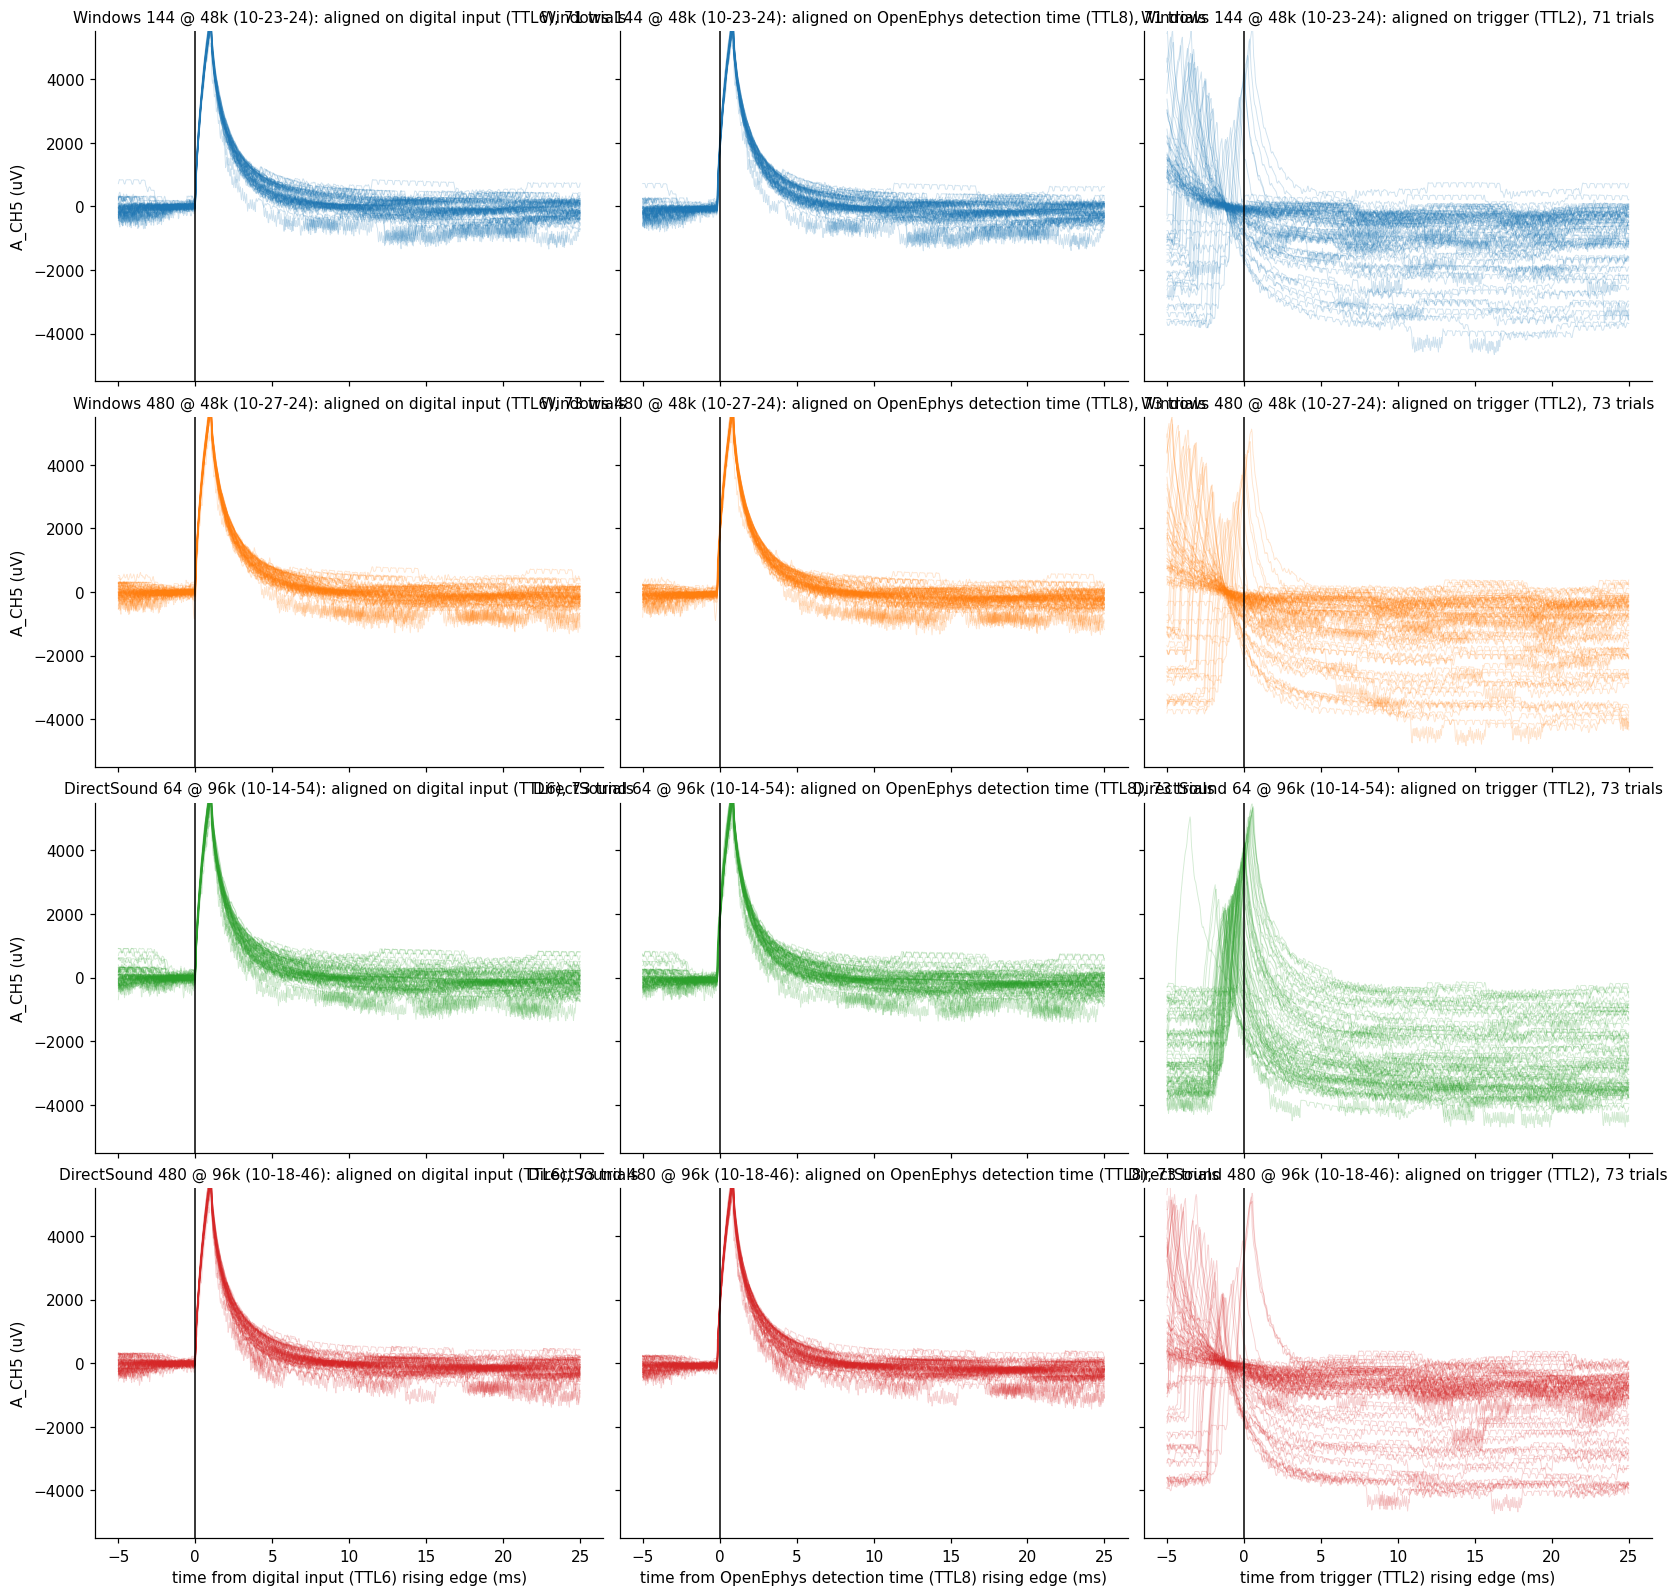

In [4]:
RAW_PRE_MS, RAW_POST_MS = 5.0, 25.0
ALIGN_ON = [("audio", f"{DIN} (TTL6)"), ("trig", f"{DET} (TTL8)"), ("stim", f"{TRG} (TTL2)")]

def cut_raw(ts, times, channel, pre_ms=RAW_PRE_MS, post_ms=RAW_POST_MS, base_ms=2.0):
    fs = float(ts.fs)
    r0, r1, nb = int(round(pre_ms / 1000 * fs)), int(round(post_ms / 1000 * fs)), int(round(base_ms / 1000 * fs))
    idx = np.searchsorted(ts.t, times, "left")
    ok = np.flatnonzero((idx - r0 >= 0) & (idx + r1 + 1 <= ts.n))
    ok = ok[np.abs(ts.t[idx[ok] + r1] - ts.t[idx[ok] - r0] - (r0 + r1) / fs) < 0.5 / fs]   # no dropped samples inside
    X = np.array([ts.block(int(i - r0), int(i + r1 + 1), [channel])[:, 0] for i in idx[ok]])
    X -= X[:, r0 - nb:r0].mean(1, keepdims=True)
    return np.arange(-r0, r1 + 1) / fs * 1000.0, X

raw = {(r["label"], key): cut_raw(r["ts"], r[key], SHOW_CHANNEL) for r in results for key, _ in ALIGN_ON}
lim = max(np.percentile(np.abs(X), 99.5) for _, X in raw.values())
fig, ax = plt.subplots(len(results), 3, figsize=(15, 3.6 * len(results)), sharex=True, sharey=True,
                       layout="constrained", squeeze=False)
for i, (r, c) in enumerate(zip(results, colors)):
    for j, (key, name) in enumerate(ALIGN_ON):
        t, X = raw[(r["label"], key)]
        a = ax[i, j]
        a.plot(t, X.T, color=c, lw=0.6, alpha=min(0.3, 15 / len(X)))
        a.axvline(0, color="k", lw=1)
        a.set_ylim(-lim, lim)
        a.set_title(f"{r['label']}: aligned on {name}, {len(X)} trials", fontsize=10)
        if i == len(results) - 1:
            a.set_xlabel(f"time from {name} rising edge (ms)")
    ax[i, 0].set_ylabel(f"{SHOW_CHANNEL} ({r['ts'].unit(SHOW_CHANNEL)})")

**Latency over the session, beside its distribution.** For each stage, every trial's latency against
when it happened, with the histogram of the same values turned on its side to the right (same latency
axis). One latency axis per stage, shared by all sessions; the red line is the median.

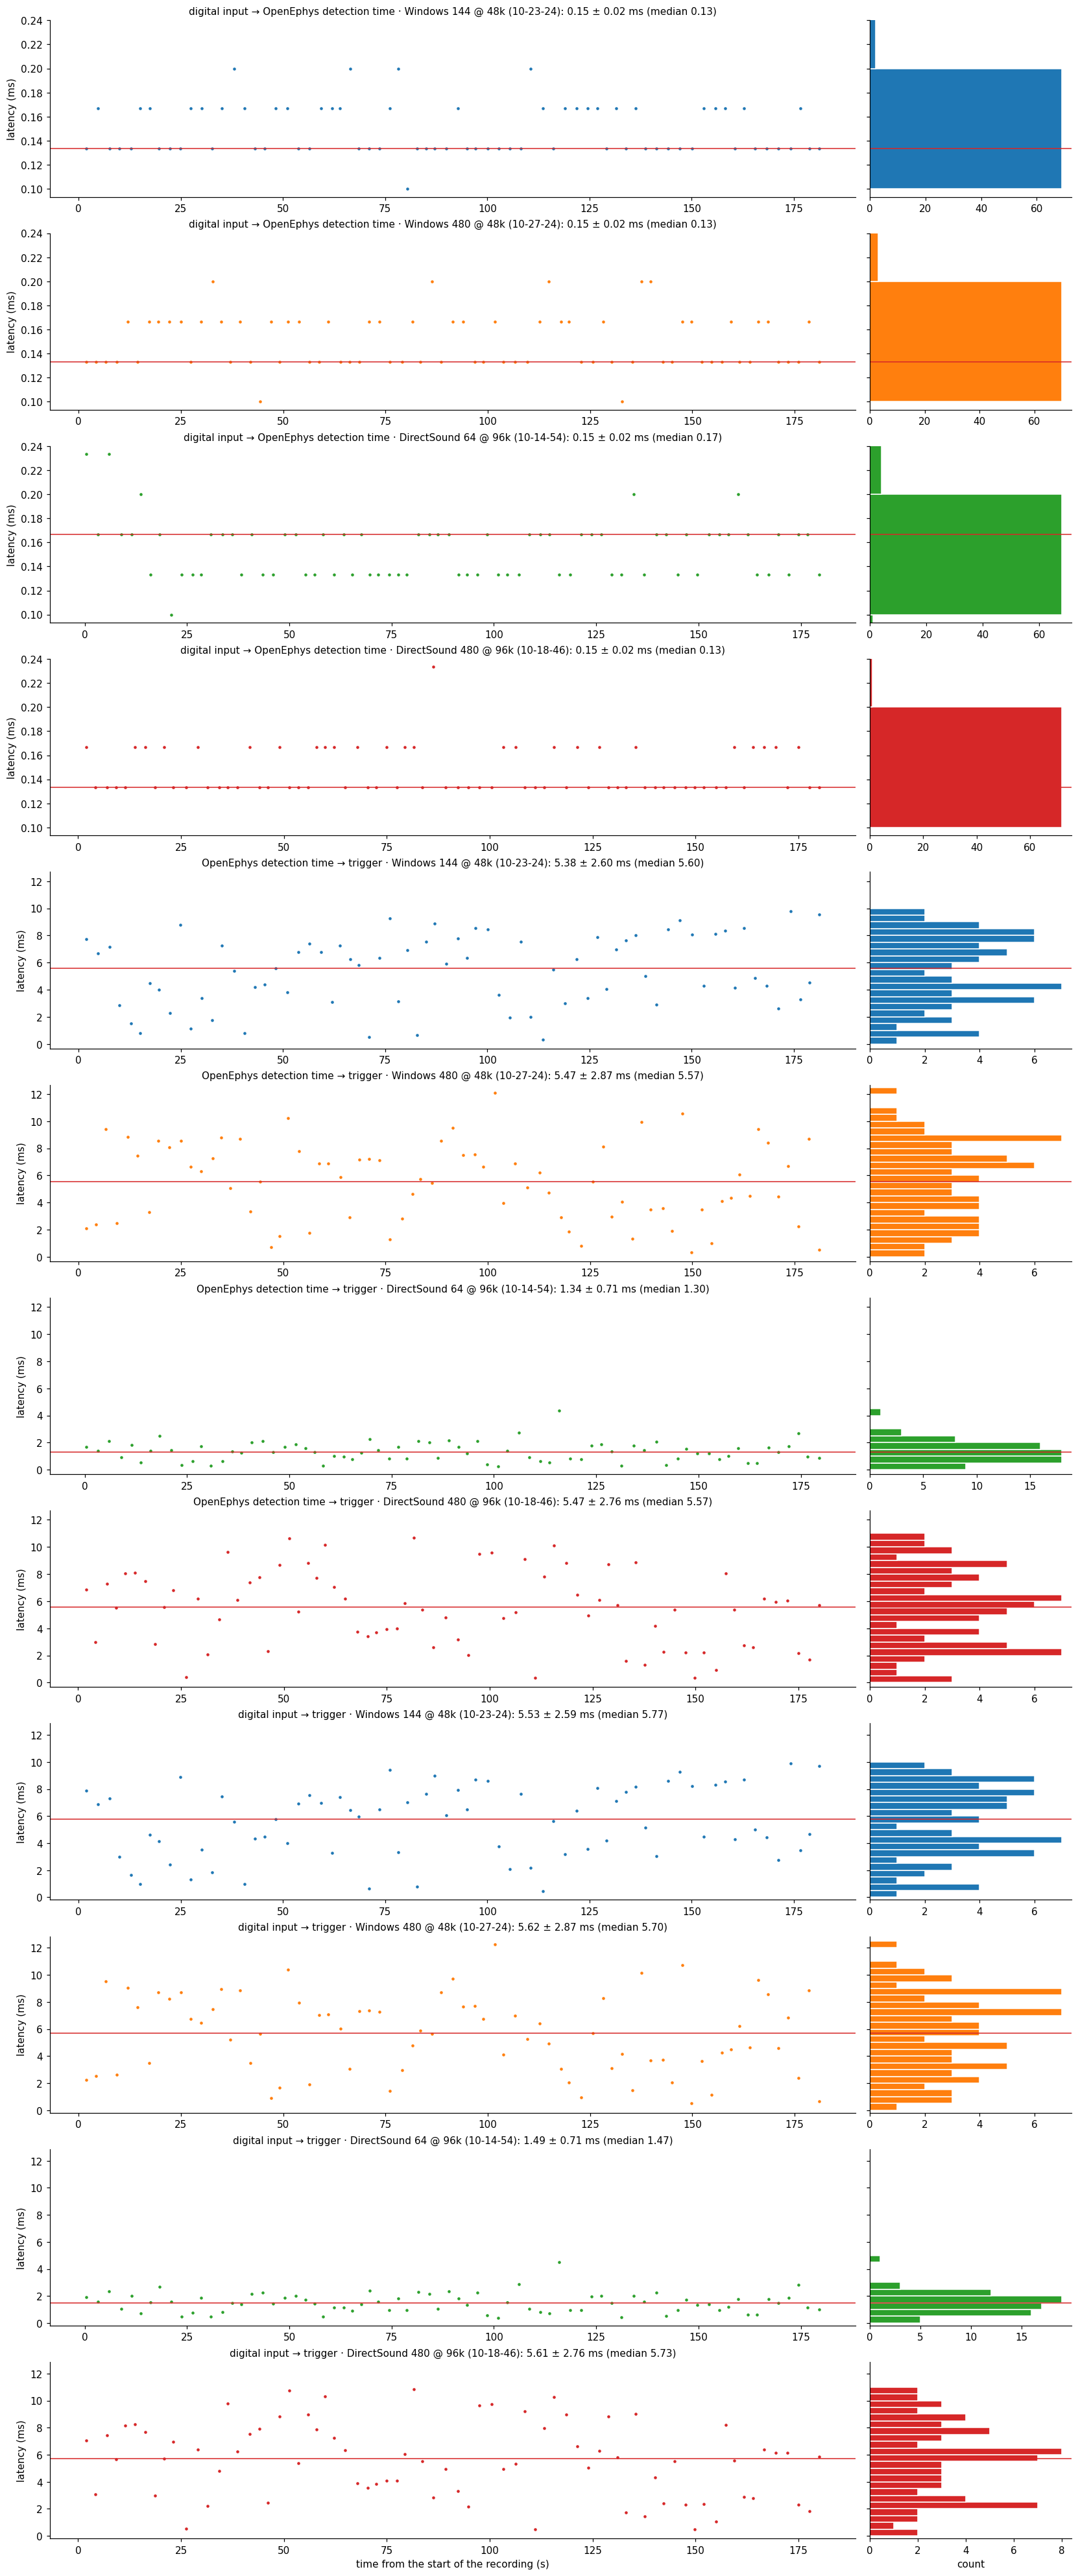

In [5]:
fig = plt.figure(figsize=(15, 3.0 * len(results) * len(STAGES)), layout="constrained")
gs = fig.add_gridspec(len(STAGES) * len(results), 2, width_ratios=[4, 1])
for si, (key, name) in enumerate(STAGES):
    vals = [r[key][np.isfinite(r[key])] for r in results]
    lo, hi = min(v.min() for v in vals), max(v.max() for v in vals)
    bw = 0.1 if hi - lo < 6 else 0.5
    bins = np.arange(np.floor(lo / bw) * bw, hi + bw, bw)
    pad = 0.05 * (hi - lo)
    for ri, (r, c) in enumerate(zip(results, colors)):
        row = si * len(results) + ri
        a0 = fig.add_subplot(gs[row, 0])
        a1 = fig.add_subplot(gs[row, 1], sharey=a0)
        ok = np.isfinite(r[key])
        ref = r["audio"] if key.startswith("a") else r["trig"]
        v = r[key][ok]
        a0.plot(ref[ok] - r["ts"].t[0], v, ".", color=c, ms=4)
        a0.axhline(np.median(v), color="C3", lw=1)
        a0.set_ylim(lo - pad, hi + pad)
        a0.set_ylabel("latency (ms)")
        a0.set_title(f"{name} · {r['label']}: {v.mean():.2f} ± {v.std():.2f} ms (median {np.median(v):.2f})", fontsize=10)
        a1.hist(v, bins=bins, orientation="horizontal", color=c, edgecolor="white", lw=0.4)
        a1.axhline(np.median(v), color="C3", lw=1)
        a1.xaxis.get_major_locator().set_params(integer=True)
        a1.tick_params(labelleft=False)
        if row == len(STAGES) * len(results) - 1:
            a0.set_xlabel("time from the start of the recording (s)"); a1.set_xlabel("count")

**The detector's input around the digital input, and its delay.** Every trial of the channel the
Ripple Detector reads, cut around the digital-input edge, with the OpenEphys detection time marked on each
trace (red). For a session whose detector reads the LFP, the broadband `SHOW_CHANNEL` is drawn behind
it in grey: the gap between the grey broadband pulse and the coloured LFP pulse is the LFP stream's
delay *as recorded*. The LFP timestamps lag what the detector actually processed (detections come before
the recorded LFP has risen), so read the delay from the detection times, not from the LFP trace.

Text(0.5, 0, 'time from digital input (TTL6) rising edge (ms)')

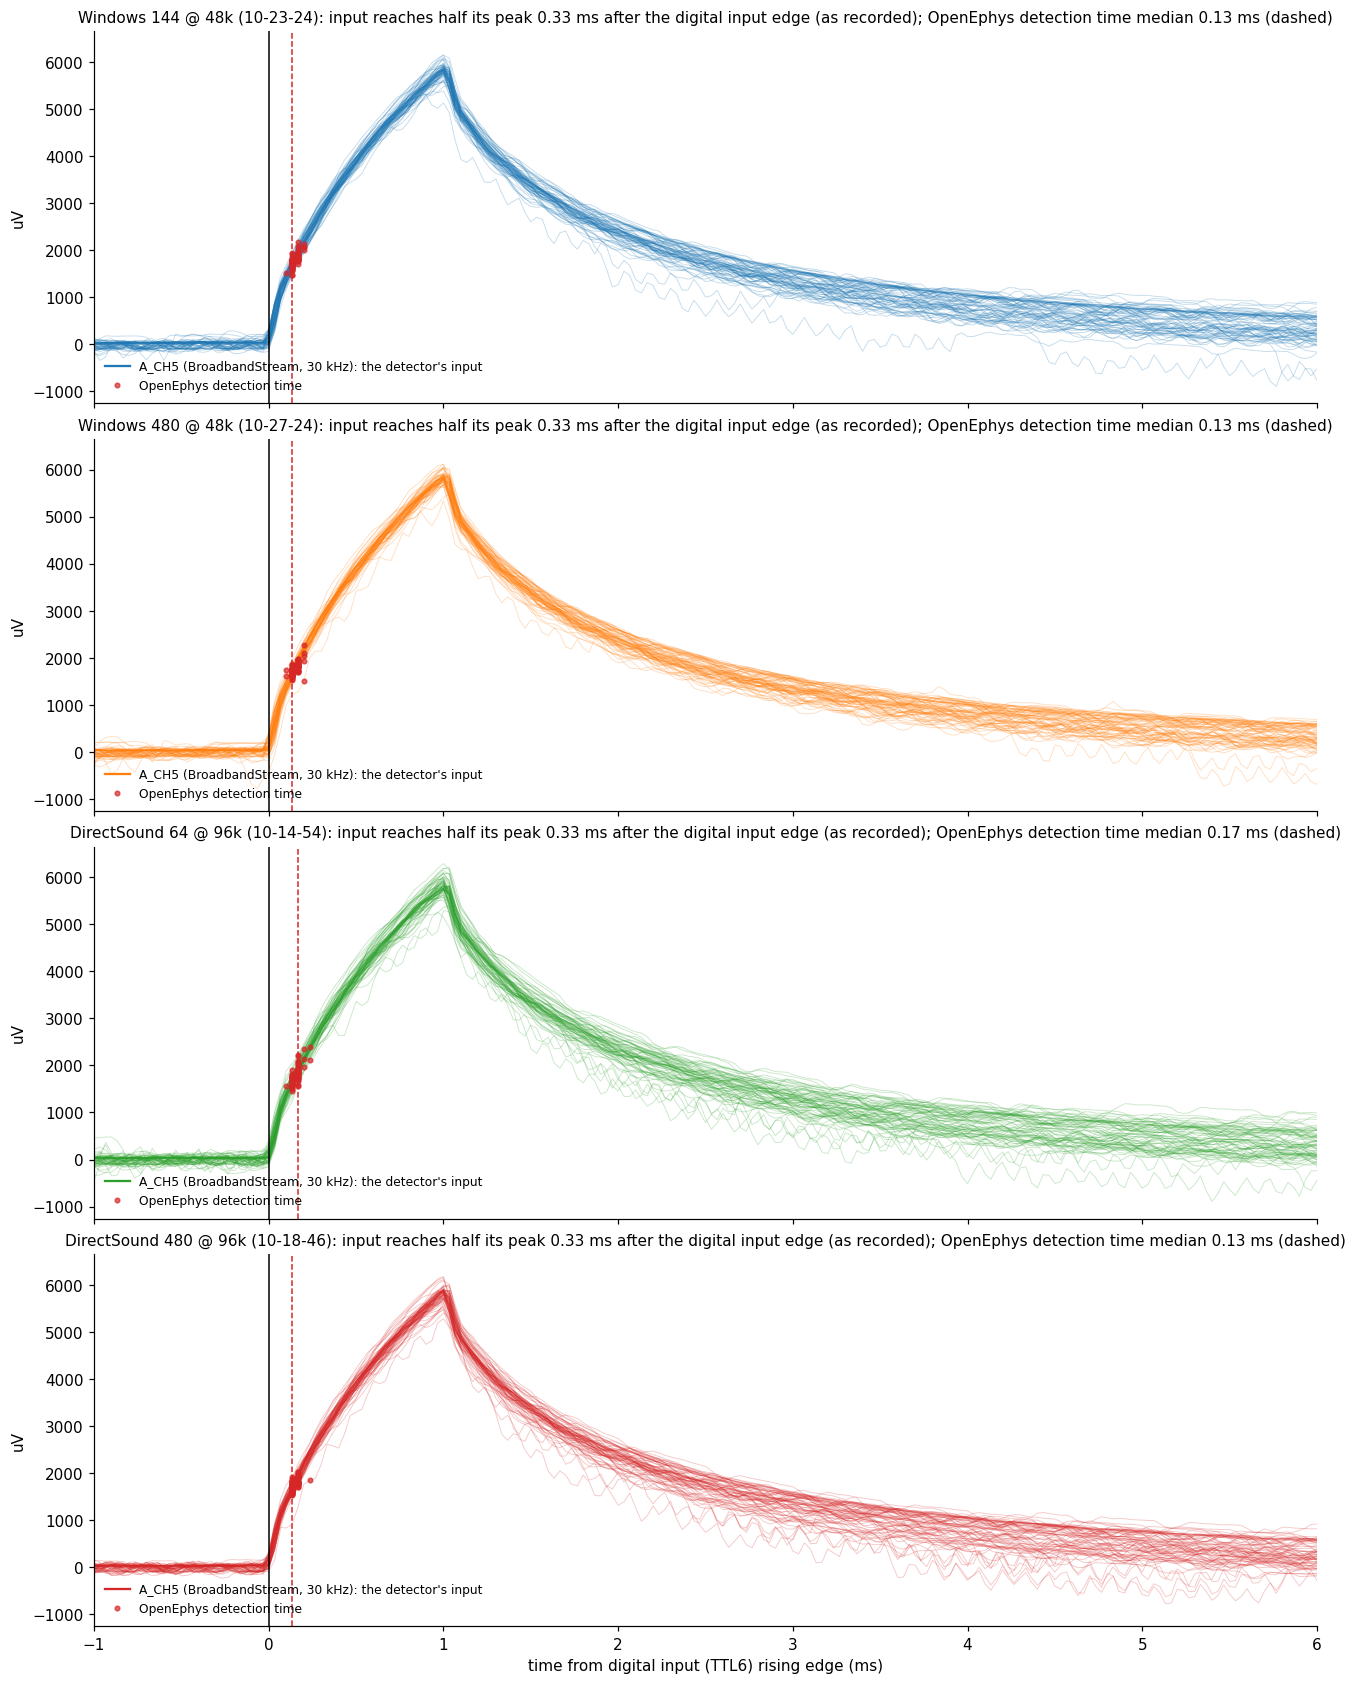

In [6]:
IN_PRE_MS, IN_POST_MS = 1.0, 6.0
fig, ax = plt.subplots(len(results), 1, figsize=(12, 3.8 * len(results)), sharex=True, sharey=True,
                       layout="constrained", squeeze=False)
for a, r, c in zip(ax[:, 0], results, colors):
    stream, ch = r["input"]
    t_in, X_in = r["in_t"], r["in_X"]
    if stream != CLOCK_STREAM or ch != SHOW_CHANNEL:
        tb, Xb = cut_raw(r["ts"], r["audio"], SHOW_CHANNEL, IN_PRE_MS, IN_POST_MS, base_ms=IN_PRE_MS)
        a.plot(tb, Xb.T, color="0.55", lw=0.5, alpha=min(0.3, 15 / len(Xb)))
        a.plot([], [], color="0.55", label=f"{SHOW_CHANNEL} (broadband, {r['ts'].fs / 1000:g} kHz)")
    a.plot(t_in, X_in.T, color=c, lw=0.6, alpha=min(0.35, 18 / len(X_in)))
    a.plot([], [], color=c, label=f"{ch} ({stream}, {r['in_fs'] / 1000:g} kHz): the detector's input")
    fire = r["a2t"][r["in_ok"]]
    ok = np.isfinite(fire)
    y = [np.interp(f, t_in, x) for f, x in zip(fire[ok], X_in[ok])]
    a.plot(fire[ok], y, "o", color="C3", ms=3, alpha=0.7, label=DET)
    m = np.median(X_in, 0)
    half = t_in[np.argmax(m > 0.5 * m.max())]
    a.axvline(0, color="k", lw=1)
    a.axvline(np.median(fire[np.isfinite(fire)]), color="C3", ls="--", lw=1)
    a.set_title(f"{r['label']}: input reaches half its peak {half:.2f} ms after the {DIN} edge (as recorded); "
                f"{DET} median {np.median(fire[np.isfinite(fire)]):.2f} ms (dashed)", fontsize=10)
    a.set_ylabel(r["in_unit"]); a.legend(frameon=False, loc="lower left", fontsize=8)
ax[-1, 0].set_xlim(-IN_PRE_MS, IN_POST_MS)
ax[-1, 0].set_xlabel(f"time from {DIN} (TTL6) rising edge (ms)")

## Summary table

Mean ± SD, median and range of each stage, and how many trials each stage matched. The last columns
say how well the 10 ms grid explains OpenEphys detection time → trigger: trials sent on the next tick,
trials that missed it and went on the one after, and the 95th percentile of how far consecutive
triggers are from a whole number of ticks.

In [7]:
def fmt(v):
    return f"{v.mean():6.2f} ± {v.std():4.2f}  med {np.median(v):5.2f}  [{v.min():5.2f}, {v.max():5.2f}]"

for key, name in STAGES:
    print(f"\n{name} (ms)")
    for r in results:
        v = r[key][np.isfinite(r[key])]
        print(f"  {r['label']:34s} n {v.size:3d}/{r[key].size:3d}   {fmt(v)}")
print(f"\n{TRG} grid")
for r in results:
    g = r["grid"]
    print(f"  {r['label']:34s} next tick {g['on_tick']}/{g['n']}, missed one {g['next_tick']}, "
          f"{TRG}s off the {GRID_MS:g} ms grid by ≤ {g['grid_err_ms']:.3f} ms (95 %)")


digital input → OpenEphys detection time (ms)
  Windows 144 @ 48k (10-23-24)       n  71/ 71     0.15 ± 0.02  med  0.13  [ 0.10,  0.20]
  Windows 480 @ 48k (10-27-24)       n  73/ 73     0.15 ± 0.02  med  0.13  [ 0.10,  0.20]
  DirectSound 64 @ 96k (10-14-54)    n  73/ 73     0.15 ± 0.02  med  0.17  [ 0.10,  0.23]
  DirectSound 480 @ 96k (10-18-46)   n  73/ 73     0.15 ± 0.02  med  0.13  [ 0.13,  0.23]

OpenEphys detection time → trigger (ms)
  Windows 144 @ 48k (10-23-24)       n  71/ 71     5.38 ± 2.60  med  5.60  [ 0.30,  9.77]
  Windows 480 @ 48k (10-27-24)       n  73/ 73     5.47 ± 2.87  med  5.57  [ 0.33, 12.10]
  DirectSound 64 @ 96k (10-14-54)    n  73/ 73     1.34 ± 0.71  med  1.30  [ 0.27,  4.37]
  DirectSound 480 @ 96k (10-18-46)   n  73/ 73     5.47 ± 2.76  med  5.57  [ 0.33, 10.70]

digital input → trigger (ms)
  Windows 144 @ 48k (10-23-24)       n  71/ 71     5.53 ± 2.59  med  5.77  [ 0.47,  9.90]
  Windows 480 @ 48k (10-27-24)       n  73/ 73     5.62 ± 2.87  med  5.7

## Latency of each stage, session by session

Same bins for every session within a stage, drawn as outlines so they overlap; dashed lines are the
medians. Bottom row: the same data as cumulative distributions, which compare sessions without
depending on the bins — the horizontal gap between two curves is the difference in latency at that
fraction of trials.

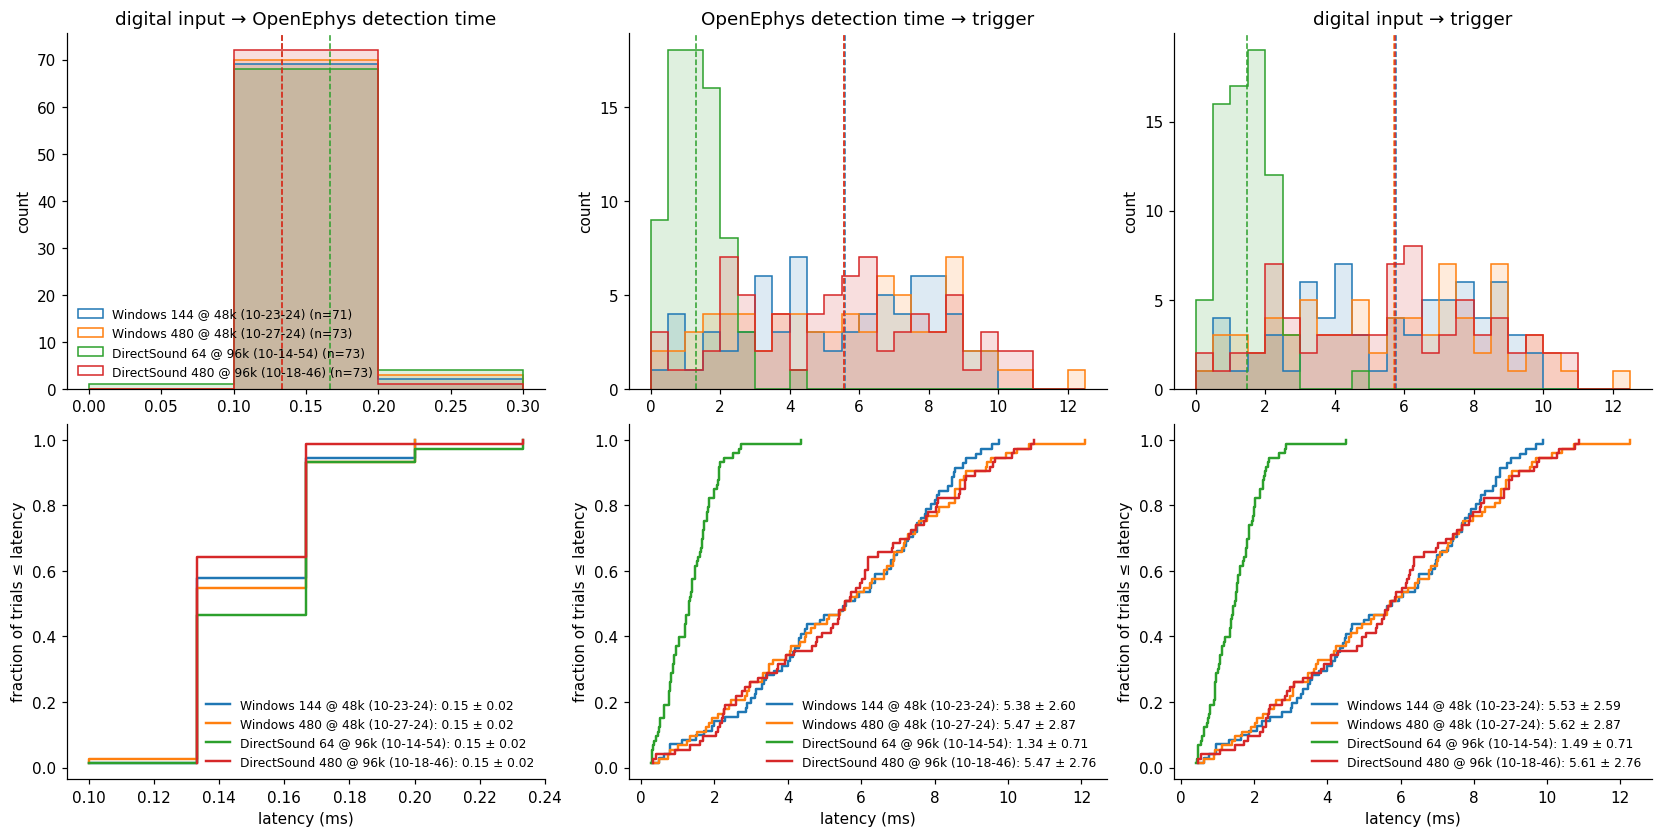

In [8]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7.5), layout="constrained")
for j, (key, name) in enumerate(STAGES):
    vals = [r[key][np.isfinite(r[key])] for r in results]
    lo, hi = min(v.min() for v in vals), max(v.max() for v in vals)
    bw = 0.1 if hi - lo < 4 else 0.5
    bins = np.arange(np.floor(lo / bw) * bw, hi + bw, bw)
    for r, v, c in zip(results, vals, colors):
        ax[0, j].hist(v, bins=bins, histtype="step", lw=1.6, color=c, label=f"{r['label']} (n={v.size})")
        ax[0, j].hist(v, bins=bins, color=c, alpha=0.15)
        ax[0, j].axvline(np.median(v), color=c, ls="--", lw=1)
        x = np.sort(v)
        ax[1, j].step(x, np.arange(1, x.size + 1) / x.size, where="post", color=c, lw=1.6,
                      label=f"{r['label']}: {v.mean():.2f} ± {v.std():.2f}")
    ax[0, j].set_title(name); ax[0, j].set_ylabel("count"); ax[0, j].yaxis.get_major_locator().set_params(integer=True)
    ax[1, j].set_xlabel("latency (ms)"); ax[1, j].set_ylabel("fraction of trials ≤ latency")
    ax[1, j].legend(frameon=False, loc="lower right", fontsize=8)
ax[0, 0].legend(frameon=False, fontsize=8)

## Are the differences real?

Mann–Whitney U on each stage for every pair of sessions (two-sided; no assumption that latencies are
normal — the wait for the trigger is roughly uniform), with the difference in medians. Levene's test asks
whether the *spread* differs, which is what matters for the jitter of a closed loop.

In [9]:
for key, name in STAGES:
    print(f"\n{name}")
    for i in range(len(results)):
        for j in range(i + 1, len(results)):
            a = results[i][key][np.isfinite(results[i][key])]
            b = results[j][key][np.isfinite(results[j][key])]
            u = stats.mannwhitneyu(a, b, alternative="two-sided")
            lev = stats.levene(a, b)
            print(f"  {results[j]['label']} − {results[i]['label']}: median {np.median(b) - np.median(a):+.3f} ms "
                  f"(Mann–Whitney p = {u.pvalue:.2g}); SD {b.std():.2f} vs {a.std():.2f} ms (Levene p = {lev.pvalue:.2g})")


digital input → OpenEphys detection time
  Windows 480 @ 48k (10-27-24) − Windows 144 @ 48k (10-23-24): median +0.000 ms (Mann–Whitney p = 0.21); SD 0.02 vs 0.02 ms (Levene p = 0.59)
  DirectSound 64 @ 96k (10-14-54) − Windows 144 @ 48k (10-23-24): median +0.033 ms (Mann–Whitney p = 0.15); SD 0.02 vs 0.02 ms (Levene p = 0.4)
  DirectSound 480 @ 96k (10-18-46) − Windows 144 @ 48k (10-23-24): median +0.000 ms (Mann–Whitney p = 0.62); SD 0.02 vs 0.02 ms (Levene p = 0.27)
  DirectSound 64 @ 96k (10-14-54) − Windows 480 @ 48k (10-27-24): median +0.033 ms (Mann–Whitney p = 0.83); SD 0.02 vs 0.02 ms (Levene p = 0.78)
  DirectSound 480 @ 96k (10-18-46) − Windows 480 @ 48k (10-27-24): median +0.000 ms (Mann–Whitney p = 0.089); SD 0.02 vs 0.02 ms (Levene p = 0.098)
  DirectSound 480 @ 96k (10-18-46) − DirectSound 64 @ 96k (10-14-54): median -0.033 ms (Mann–Whitney p = 0.064); SD 0.02 vs 0.02 ms (Levene p = 0.045)

OpenEphys detection time → trigger
  Windows 480 @ 48k (10-27-24) − Windows 144 @

## What the detector saw

The detector's input channel around each digital-input edge (median and 10–90 % band across trials,
each on its own stream's time axis), with the distribution of OpenEphys detection times below it. The
broadband input rises within a sample of the digital-input edge; the LFP input arrives later because of
the LFP filter and decimation. **The LFP trace's timing is approximate**: in the LFP sessions detections
precede the recorded LFP rise, so the LFP stream's timestamps lag what the detector processed —
the detection times (on the broadband clock) are the measurement to trust.

(-1.0, 6.0)

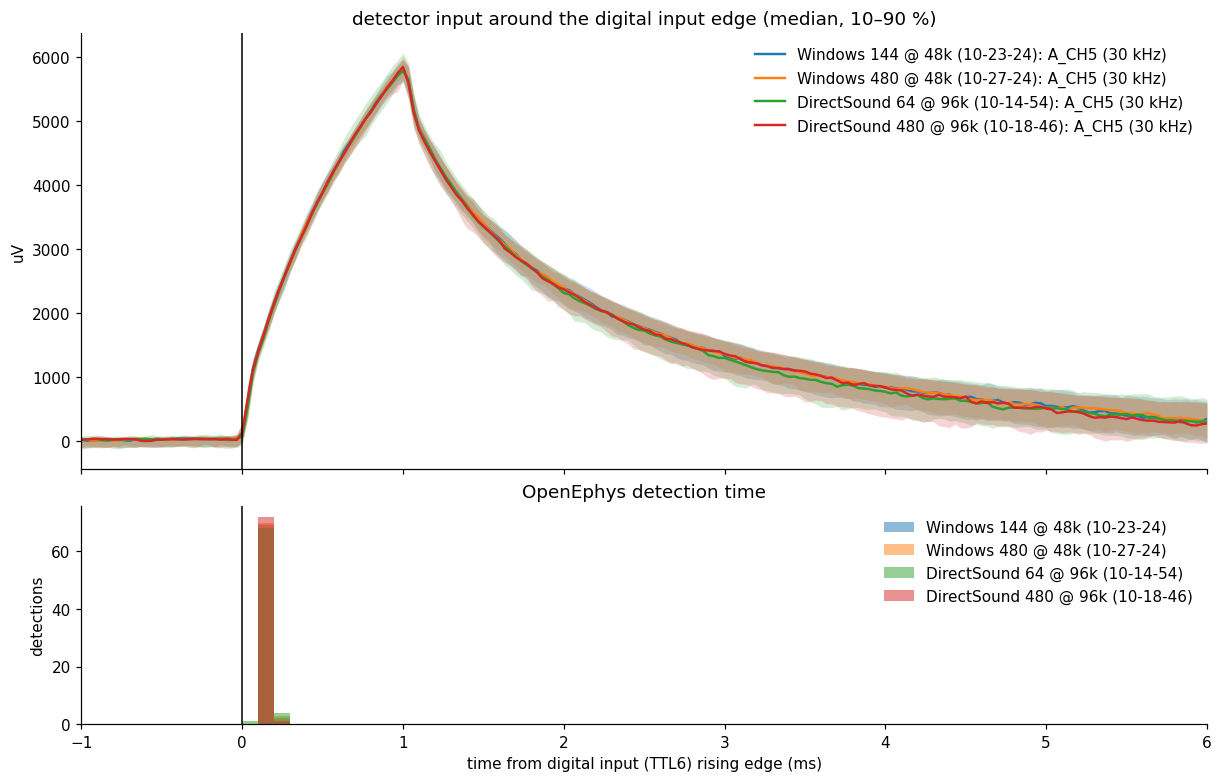

In [10]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, layout="constrained", gridspec_kw={"height_ratios": [2, 1]})
for r, c in zip(results, colors):
    t, X = r["in_t"], r["in_X"]
    q10, q50, q90 = np.percentile(X, [10, 50, 90], axis=0)
    ax[0].fill_between(t, q10, q90, color=c, alpha=0.2, lw=0)
    ax[0].plot(t, q50, color=c, lw=1.6, label=f"{r['label']}: {r['input'][1]} ({r['in_fs'] / 1000:g} kHz)")
    v = r["a2t"][np.isfinite(r["a2t"])]
    ax[1].hist(v, bins=np.arange(-1, 6.05, 0.1), color=c, alpha=0.5, label=r["label"])
ax[0].axvline(0, color="k", lw=1); ax[1].axvline(0, color="k", lw=1)
ax[0].set_ylabel(results[0]["in_unit"]); ax[0].legend(frameon=False, loc="upper right")
ax[0].set_title(f"detector input around the {DIN} edge (median, 10–90 %)")
ax[1].set_xlabel(f"time from {DIN} (TTL6) rising edge (ms)"); ax[1].set_ylabel("detections")
ax[1].set_title(DET); ax[1].legend(frameon=False)
ax[1].set_xlim(-1, 6)

## The trigger's grid in every session

OpenEphys detection time → trigger against the wait from the detection to the next 10 ms tick. Points on the diagonal
were sent on the next tick; points 10 ms above it missed that tick. If a session's points sit on the
diagonal, its detection → trigger latency is set by when the detection fell within the grid, not by the
signal path, and only the digital input → detection stage differs between paths.

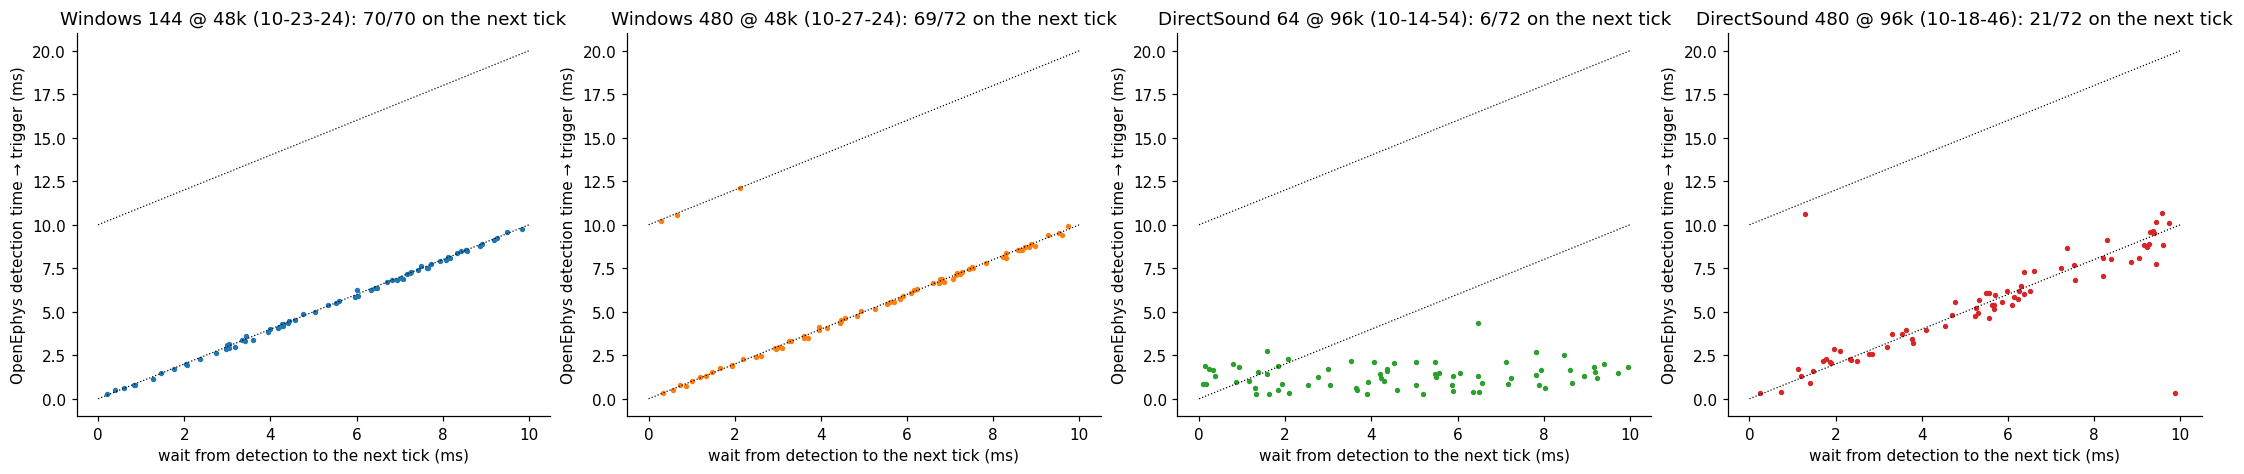

In [11]:
fig, ax = plt.subplots(1, len(results), figsize=(5 * len(results), 4.2), layout="constrained", squeeze=False)
for a, r, c in zip(ax[0], results, colors):
    g = r["grid"]
    a.plot(g["wait"], g["lat"], ".", color=c, ms=5)
    a.plot([0, GRID_MS], [0, GRID_MS], "k:", lw=0.8)
    a.plot([0, GRID_MS], [GRID_MS, 2 * GRID_MS], "k:", lw=0.8)
    a.set_xlabel("wait from detection to the next tick (ms)"); a.set_ylabel(f"{DET} → {TRG} (ms)")
    a.set_title(f"{r['label']}: {g['on_tick']}/{g['n']} on the next tick")

## Groups

Sessions that share a setting are pooled by their `group` (in `SESSIONS`; sessions without one are left
out here): each stage's trials from all sessions of a group together, the same table, histograms and
cumulative distributions per group, and Mann–Whitney / Levene between every pair of groups. Pooling
assumes the sessions of a group differ only in what the group ignores — check the per-session rows
above first, a session that stands apart within its group says the grouping hides something.


digital input → OpenEphys detection time (ms)
  Windows Audio          2 sessions, n 144     0.15 ± 0.02  med  0.13  [ 0.10,  0.20]
      Windows 144 @ 48k (10-23-24)         0.15 ± 0.02  med  0.13
      Windows 480 @ 48k (10-27-24)         0.15 ± 0.02  med  0.13
  DirectSound            2 sessions, n 146     0.15 ± 0.02  med  0.13  [ 0.10,  0.23]
      DirectSound 64 @ 96k (10-14-54)      0.15 ± 0.02  med  0.17
      DirectSound 480 @ 96k (10-18-46)     0.15 ± 0.02  med  0.13
  DirectSound − Windows Audio: median +0.000 ms (Mann–Whitney p = 0.85); SD 0.02 vs 0.02 ms (Levene p = 0.92)

OpenEphys detection time → trigger (ms)
  Windows Audio          2 sessions, n 144     5.42 ± 2.74  med  5.58  [ 0.30, 12.10]
      Windows 144 @ 48k (10-23-24)         5.38 ± 2.60  med  5.60
      Windows 480 @ 48k (10-27-24)         5.47 ± 2.87  med  5.57
  DirectSound            2 sessions, n 146     3.40 ± 2.88  med  2.12  [ 0.27, 10.70]
      DirectSound 64 @ 96k (10-14-54)      1.34 ± 0.71  med  1

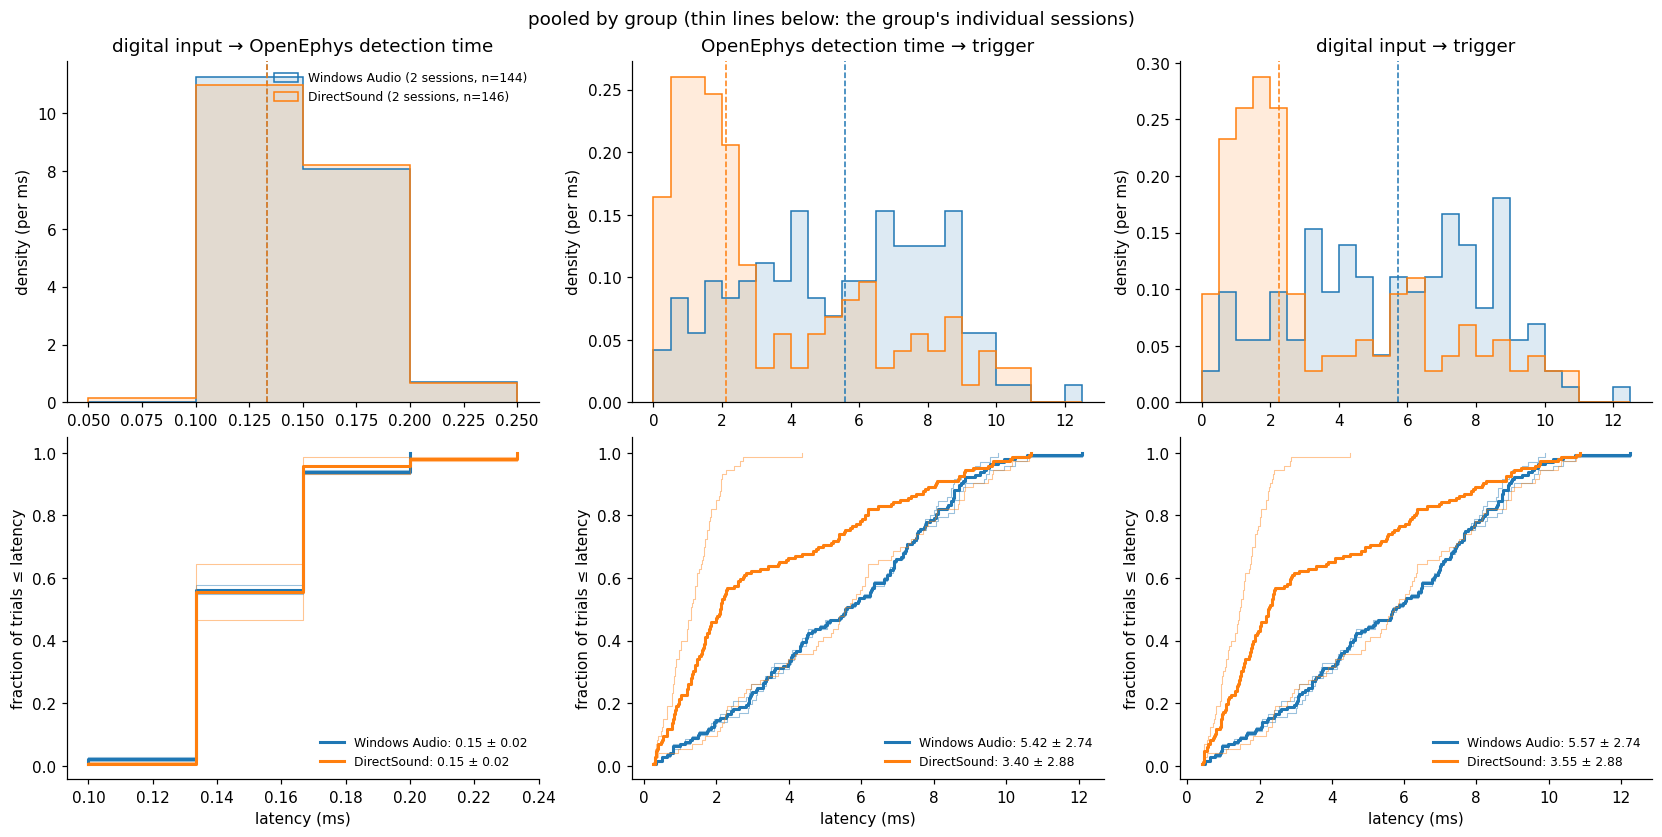

In [12]:
groups = {}
for r in results:
    if r.get("group"):
        groups.setdefault(r["group"], []).append(r)
if len(groups) < 2:
    print("fewer than two groups: nothing to compare")
else:
    pooled = {g: {key: np.concatenate([r[key][np.isfinite(r[key])] for r in rs]) for key, _ in STAGES} for g, rs in groups.items()}
    gcolors = {g: f"C{i}" for i, g in enumerate(groups)}
    for key, name in STAGES:
        print(f"\n{name} (ms)")
        for g, rs in groups.items():
            v = pooled[g][key]
            print(f"  {g:22s} {len(rs)} sessions, n {v.size:3d}   {fmt(v)}")
            for r in rs:
                w = r[key][np.isfinite(r[key])]
                print(f"      {r['label']:34s} {w.mean():6.2f} ± {w.std():4.2f}  med {np.median(w):5.2f}")
        names = list(groups)
        for i in range(len(names)):
            for j in range(i + 1, len(names)):
                a, b = pooled[names[i]][key], pooled[names[j]][key]
                print(f"  {names[j]} − {names[i]}: median {np.median(b) - np.median(a):+.3f} ms "
                      f"(Mann–Whitney p = {stats.mannwhitneyu(a, b, alternative='two-sided').pvalue:.2g}); "
                      f"SD {b.std():.2f} vs {a.std():.2f} ms (Levene p = {stats.levene(a, b).pvalue:.2g})")

    fig, ax = plt.subplots(2, 3, figsize=(15, 7.5), layout="constrained")
    for j, (key, name) in enumerate(STAGES):
        vals = list(pooled[g][key] for g in groups)
        lo, hi = min(v.min() for v in vals), max(v.max() for v in vals)
        bw = 0.05 if hi - lo < 1.5 else 0.1 if hi - lo < 6 else 0.5
        bins = np.arange(np.floor(lo / bw) * bw, hi + bw, bw)
        for g, rs in groups.items():
            v, c = pooled[g][key], gcolors[g]
            ax[0, j].hist(v, bins=bins, histtype="step", lw=1.8, color=c, density=True, label=f"{g} ({len(rs)} sessions, n={v.size})")
            ax[0, j].hist(v, bins=bins, color=c, alpha=0.15, density=True)
            ax[0, j].axvline(np.median(v), color=c, ls="--", lw=1)
            x = np.sort(v)
            ax[1, j].step(x, np.arange(1, x.size + 1) / x.size, where="post", color=c, lw=2, label=f"{g}: {v.mean():.2f} ± {v.std():.2f}")
            for r in rs:                                   # each session of the group, thin, behind the pooled curve
                w = np.sort(r[key][np.isfinite(r[key])])
                ax[1, j].step(w, np.arange(1, w.size + 1) / w.size, where="post", color=c, lw=0.7, alpha=0.45)
        ax[0, j].set_title(name); ax[0, j].set_ylabel("density (per ms)")
        ax[1, j].set_xlabel("latency (ms)"); ax[1, j].set_ylabel("fraction of trials ≤ latency")
        ax[1, j].legend(frameon=False, loc="lower right", fontsize=8)
    ax[0, 0].legend(frameon=False, fontsize=8)
    fig.suptitle("pooled by group (thin lines below: the group's individual sessions)")